# Effect of Training Data Size

Use TF-IDF + Logistic Regression with the same settings as the baseline. Keep the saved 2,000-row validation set fixed and train on five sizes from the 8,000-row training split.

Run all cells from top to bottom.

## 1. Imports and Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

RANDOM_STATE = 42
training_sizes = [500, 1000, 2000, 5000, 8000]

# work from the project folder or notebooks folder
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

## 2. Load the Saved Split

Use the same training and validation IDs as the baseline.

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
train_ids = pd.read_csv(OUTPUT_DIR / "train_ids.csv")
val_ids = pd.read_csv(OUTPUT_DIR / "validation_ids.csv")

# keep the saved row order
train = train.set_index("id")
train_split = train.loc[train_ids["id"]].reset_index()
val_split = train.loc[val_ids["id"]].reset_index()

assert len(train_split) == 8000 and len(val_split) == 2000
assert set(train_split["id"]).isdisjoint(val_split["id"])

X_val = val_split["text"].fillna("")
y_val = val_split["label"]

print("Training examples:", len(train_split))
print("Validation examples:", len(val_split))

Training examples: 8000
Validation examples: 2000


## 3. Define the Baseline Model

Keep all hyperparameters unchanged. Each model learns TF-IDF features only from its own training sample.

In [3]:
baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=50000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

## 4. Q2.1: Train with Different Data Sizes

Create smaller samples from larger ones, keeping class proportions similar. This makes the samples nested: every larger sample contains the smaller ones. Use seed 42 for reproducibility.

In [4]:
# create the training samples
samples = {8000: train_split}
subset = train_split

for size in [5000, 2000, 1000, 500]:
    subset, _ = train_test_split(
        subset,
        train_size=size,
        random_state=RANDOM_STATE,
        stratify=subset["label"]
    )
    samples[size] = subset

# save sample IDs for future reference
sample_ids = []
for size in training_sizes:
    ids = samples[size][["id"]].copy()
    ids["training_rows"] = size
    sample_ids.append(ids)

pd.concat(sample_ids).to_csv(
    OUTPUT_DIR / "learning_curve_subset_ids.csv", index=False
)

In [5]:
results = []

for size in training_sizes:
    subset = samples[size]
    X_train = subset["text"].fillna("")
    y_train = subset["label"]

    # train a fresh copy of the same model
    model = clone(baseline_model)
    model.fit(X_train, y_train)

    train_probs = model.predict_proba(X_train)[:, 1]
    val_probs = model.predict_proba(X_val)[:, 1]

    train_auc = roc_auc_score(y_train, train_probs)
    val_auc = roc_auc_score(y_val, val_probs)

    results.append({
        "training_rows": size,
        "train_auc": train_auc,
        "validation_auc": val_auc,
        "auc_gap": train_auc - val_auc
    })

    print(f"{size} rows: Training AUROC = {train_auc:.4f}, Validation AUROC = {val_auc:.4f}")

learning_curve_results = pd.DataFrame(results)
learning_curve_results.to_csv(
    OUTPUT_DIR / "learning_curve_results.csv", index=False
)

display(learning_curve_results.round(4))

500 rows: Training AUROC = 1.0000, Validation AUROC = 0.8611
1000 rows: Training AUROC = 1.0000, Validation AUROC = 0.8871
2000 rows: Training AUROC = 0.9996, Validation AUROC = 0.9082
5000 rows: Training AUROC = 0.9958, Validation AUROC = 0.9281
8000 rows: Training AUROC = 0.9932, Validation AUROC = 0.9361


,training_rows,train_auc,validation_auc,auc_gap
0,500,1.0000,0.8611,0.1389
1,1000,1.0000,0.8871,0.1129
2,2000,0.9996,0.9082,0.0914
3,5000,0.9958,0.9281,0.0678
4,8000,0.9932,0.9361,0.0571


## 5. Q2.2: Plot the Learning Curve

Compare training and validation AUROC as training size increases.

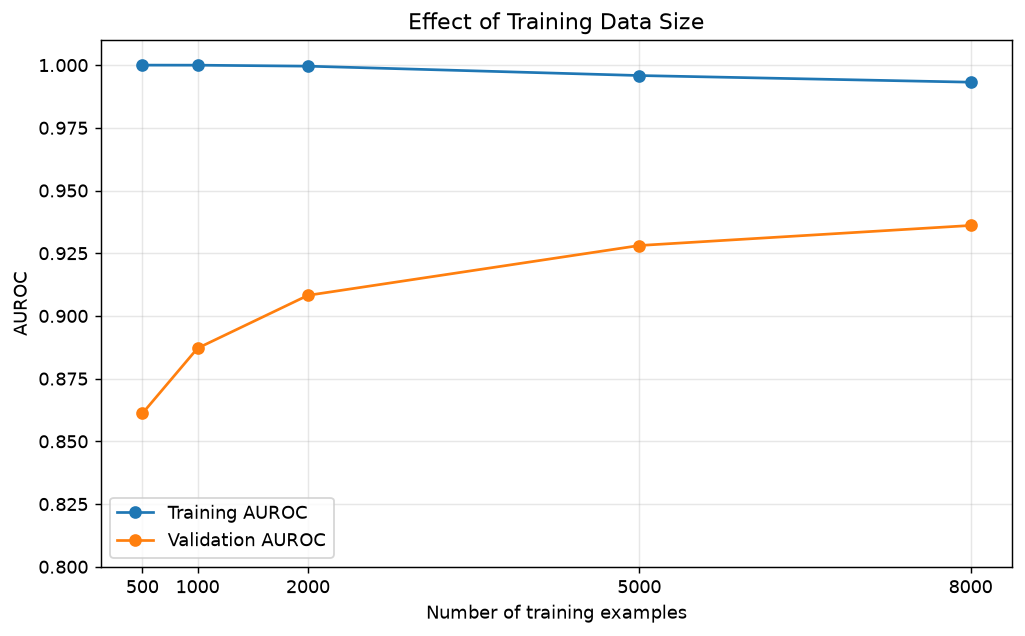

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    learning_curve_results["training_rows"],
    learning_curve_results["train_auc"],
    marker="o",
    label="Training AUROC"
)

plt.plot(
    learning_curve_results["training_rows"],
    learning_curve_results["validation_auc"],
    marker="o",
    label="Validation AUROC"
)

plt.xlabel("Number of training examples")
plt.ylabel("AUROC")
plt.title("Effect of Training Data Size")
plt.xticks(training_sizes)
plt.ylim(0.8, 1.01)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "learning_curve.png", dpi=200)
plt.savefig(OUTPUT_DIR / "learning_curve.pdf")
plt.show()

## 6. Q2.3: Interpretation

With 500 labeled examples, training AUROC is 1.0000, but validation AUROC is only 0.8611, indicating overfitting: the model ranks its training examples almost perfectly but generalizes less well. As training size increases to 8,000, validation AUROC rises to 0.9361, while training AUROC declines slightly to 0.9932. The training-validation gap narrows from 0.1389 to 0.0571. This pattern suggests that additional labeled examples improve generalization and reduce overfitting. There is no clear evidence of severe underfitting, since training performance remains high. Validation gains become smaller at larger sample sizes, suggesting diminishing returns, although more labels may still help. Because each size uses one nested, stratified sample and one fixed validation set, the curve does not measure sampling variability or guarantee the same improvement on unseen test data.